# Implementation and Time Analysis of Kruskal's Algorithm (Minimum Spanning Tree)

**Problem:** Given a connected, undirected, **weighted** graph, find a
**Minimum Spanning Tree (MST)** — a subset of edges that connects all vertices,
contains no cycles, and has the **minimum possible total edge weight**.

**Kruskal's Algorithm (greedy):**
1. Sort **all edges** by weight, smallest first.
2. Go through the sorted edges one by one.
3. Add an edge to the MST **only if it does not create a cycle** with the edges already chosen.
4. Stop once the MST has `V - 1` edges.

To check "does this edge create a cycle?" quickly, we use a **Disjoint Set Union
(Union-Find)** data structure that tracks which vertices are already connected.

This notebook covers:
- Union-Find with **path compression** and **union by rank**
- Kruskal's algorithm with a step-by-step log (which edges were accepted/rejected and why)
- User input (enter your own weighted edges)
- Runtime measurement, time complexity, and space complexity
- Visualization of the graph with the MST highlighted
- Verification against `networkx`'s built-in MST
- A runtime comparison of Kruskal's vs Prim's on sparse and dense graphs


In [1]:
# Common imports used throughout the notebook
import time
import heapq
import random
from collections import defaultdict
import matplotlib.pyplot as plt
import networkx as nx


def get_user_edges(demo_string=None):
    """Takes weighted edges as 'u,v,w' triples separated by semicolons.

    Example: A,B,4;A,C,3;B,C,1   -> edges A-B (4), A-C (3), B-C (1)

    - Interactive use: call get_user_edges() with NO arguments to be prompted.
    - Notebook demo cells pass a fixed string so the notebook runs end-to-end
      with baked-in outputs. Remove the argument to type your own graph.
    """
    raw = demo_string if demo_string is not None else input(
        "Enter edges as u,v,weight separated by semicolons (e.g., A,B,4;A,C,3;B,C,1): "
    )
    edges = []
    try:
        for triple in raw.split(';'):
            triple = triple.strip()
            if not triple:
                continue
            u, v, w = [x.strip() for x in triple.split(',')]
            edges.append((u, v, int(w)))
        if not edges:
            raise ValueError
    except ValueError:
        print("Invalid input detected, using a default sample graph instead.")
        edges = [('A', 'B', 4), ('A', 'C', 3), ('B', 'C', 1), ('B', 'D', 2),
                 ('C', 'D', 4), ('D', 'E', 2), ('C', 'E', 5)]
    return edges


def nodes_from_edges(edges):
    seen = []
    for u, v, _ in edges:
        for x in (u, v):
            if x not in seen:
                seen.append(x)
    return seen


## 1. Union-Find (Disjoint Set Union)

Union-Find maintains a collection of disjoint sets and supports two operations:
- `find(x)` — which set does `x` belong to? (returns the set's representative/root)
- `union(x, y)` — merge the sets containing `x` and `y`

Kruskal's uses it for cycle detection: an edge `(u, v)` creates a cycle **if and
only if** `find(u) == find(v)` (they're already connected). Otherwise we accept
the edge and `union(u, v)`.

Two optimizations make it nearly constant time per operation:
- **Path compression:** during `find`, point every visited node directly at the root
- **Union by rank:** always attach the shorter tree under the taller one


In [2]:
class UnionFind:
    def __init__(self, items):
        self.parent = {x: x for x in items}
        self.rank = {x: 0 for x in items}

    def find(self, x):
        if self.parent[x] != x:
            self.parent[x] = self.find(self.parent[x])   # path compression
        return self.parent[x]

    def union(self, x, y):
        root_x, root_y = self.find(x), self.find(y)
        if root_x == root_y:
            return False   # already in the same set -> would create a cycle

        # union by rank: attach the lower-rank root under the higher-rank root
        if self.rank[root_x] < self.rank[root_y]:
            root_x, root_y = root_y, root_x
        self.parent[root_y] = root_x
        if self.rank[root_x] == self.rank[root_y]:
            self.rank[root_x] += 1
        return True


In [3]:
# --- Quick Union-Find demo ---
uf = UnionFind(['A', 'B', 'C', 'D'])
print("union(A, B):", uf.union('A', 'B'))        # True  -> merged
print("union(C, D):", uf.union('C', 'D'))        # True  -> merged
print("find(A) == find(B):", uf.find('A') == uf.find('B'))   # True
print("find(A) == find(C):", uf.find('A') == uf.find('C'))   # False
print("union(A, B):", uf.union('A', 'B'))        # False -> already connected (cycle!)


union(A, B): True
union(C, D): True
find(A) == find(B): True
find(A) == find(C): False
union(A, B): False


## 2. Kruskal's Algorithm

In [4]:
def kruskal(nodes, edges, verbose=False):
    """Returns (mst_edges, total_weight). Optionally prints each decision."""
    uf = UnionFind(nodes)
    mst_edges = []
    total_weight = 0

    sorted_edges = sorted(edges, key=lambda e: e[2])   # sort by weight

    for u, v, w in sorted_edges:
        if uf.union(u, v):
            mst_edges.append((u, v, w))
            total_weight += w
            if verbose:
                print(f"  ACCEPT  {u} - {v}  (weight {w})")
            if len(mst_edges) == len(nodes) - 1:
                break   # MST complete: V - 1 edges
        elif verbose:
            print(f"  reject  {u} - {v}  (weight {w})  -> would create a cycle")

    return mst_edges, total_weight


In [5]:
# --- Kruskal's: User Input + Runtime ---
# Replace the argument below with nothing, i.e. get_user_edges(),
# to type your own weighted graph interactively.
edges = get_user_edges("A,B,4;A,C,3;B,C,1;B,D,2;C,D,4;D,E,2;C,E,5")
nodes = nodes_from_edges(edges)

print("Graph edges (u, v, weight):")
for e in edges:
    print("  ", e)

print("\nEdges sorted by weight:")
for e in sorted(edges, key=lambda e: e[2]):
    print("  ", e)

print("\nProcessing edges in sorted order:")
t0 = time.time()
mst_edges, total_weight = kruskal(nodes, edges, verbose=True)
t1 = time.time()

print("\nMST edges:")
for u, v, w in mst_edges:
    print(f"  {u} - {v}  (weight {w})")
print(f"\nTotal MST weight : {total_weight}")
print(f"Runtime          : {(t1 - t0) * 1000:.4f} ms (includes the verbose printing)")


Graph edges (u, v, weight):
   ('A', 'B', 4)
   ('A', 'C', 3)
   ('B', 'C', 1)
   ('B', 'D', 2)
   ('C', 'D', 4)
   ('D', 'E', 2)
   ('C', 'E', 5)

Edges sorted by weight:
   ('B', 'C', 1)
   ('B', 'D', 2)
   ('D', 'E', 2)
   ('A', 'C', 3)
   ('A', 'B', 4)
   ('C', 'D', 4)
   ('C', 'E', 5)

Processing edges in sorted order:
  ACCEPT  B - C  (weight 1)
  ACCEPT  B - D  (weight 2)
  ACCEPT  D - E  (weight 2)
  ACCEPT  A - C  (weight 3)

MST edges:
  B - C  (weight 1)
  B - D  (weight 2)
  D - E  (weight 2)
  A - C  (weight 3)

Total MST weight : 8
Runtime          : 0.0715 ms (includes the verbose printing)


In [6]:
# --- Clean runtime measurement (no printing inside the timed region) ---
t0 = time.time()
_ = kruskal(nodes, edges)
t1 = time.time()
print(f"Kruskal's runtime (no printing): {(t1 - t0) * 1000:.6f} ms")


Kruskal's runtime (no printing): 0.049591 ms


**Time Complexity:** `O(E log E)` — dominated by sorting the `E` edges. The
loop over sorted edges does `E` union-find operations, each taking
near-constant `O(α(V))` amortized time (where `α` is the extremely slowly
growing inverse Ackermann function, effectively ≤ 4 for any realistic input).
Since `E ≤ V²`, `log E = O(log V)`, so this is equivalently `O(E log V)`.

**Space Complexity:** `O(V + E)` — for the sorted edge list and the
Union-Find `parent`/`rank` arrays.


## 3. Visualizing the Graph and its Minimum Spanning Tree

Edges chosen for the MST are drawn thick and in red; all other edges are thin
and gray. Edge labels show weights.


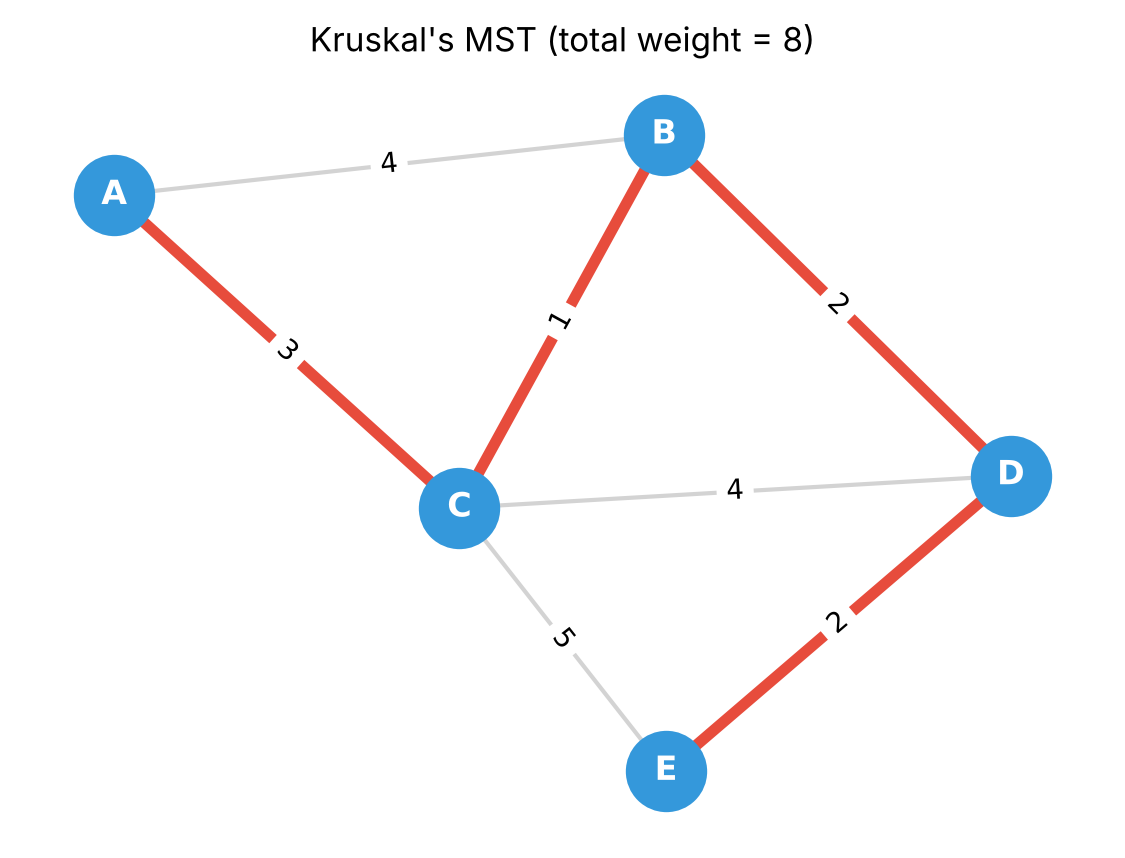

In [7]:
def draw_mst(edges, mst_edges, title):
    G = nx.Graph()
    for u, v, w in edges:
        G.add_edge(u, v, weight=w)

    pos = nx.spring_layout(G, seed=7)
    mst_set = {frozenset((u, v)) for u, v, _ in mst_edges}
    mst_list = [(u, v) for u, v in G.edges() if frozenset((u, v)) in mst_set]
    other_list = [(u, v) for u, v in G.edges() if frozenset((u, v)) not in mst_set]

    fig, ax = plt.subplots(figsize=(7, 5))
    nx.draw_networkx_nodes(G, pos, node_color='#3498db', node_size=800, ax=ax)
    nx.draw_networkx_labels(G, pos, font_color='white', font_weight='bold', ax=ax)
    nx.draw_networkx_edges(G, pos, edgelist=other_list, edge_color='lightgray', width=1.5, ax=ax)
    nx.draw_networkx_edges(G, pos, edgelist=mst_list, edge_color='#e74c3c', width=4, ax=ax)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, 'weight'), ax=ax)
    ax.set_title(title)
    ax.axis('off')
    plt.show()


draw_mst(edges, mst_edges, f"Kruskal's MST (total weight = {total_weight})")


## 4. Verification against `networkx`

The MST's **total weight** is unique even if several different trees tie for
the minimum, so that is what we compare against `networkx`'s built-in MST.


In [8]:
G_nx = nx.Graph()
for u, v, w in edges:
    G_nx.add_edge(u, v, weight=w)

nx_mst = nx.minimum_spanning_tree(G_nx, algorithm='kruskal')
nx_total = sum(d['weight'] for _, _, d in nx_mst.edges(data=True))

print(f"Our Kruskal's total weight : {total_weight}")
print(f"networkx MST total weight  : {nx_total}")
print("Match!" if total_weight == nx_total else "MISMATCH!")
print(f"\nMST has {len(mst_edges)} edges for {len(nodes)} vertices (always V - 1 = {len(nodes) - 1})")


Our Kruskal's total weight : 8
networkx MST total weight  : 8
Match!

MST has 4 edges for 5 vertices (always V - 1 = 4)


### Disconnected graphs: Minimum Spanning Forest

If the graph is **not connected**, no spanning tree exists. Kruskal's still
works naturally — it just produces a **minimum spanning forest** (one MST per
connected component), with fewer than `V - 1` edges in total. Unlike Prim's,
which only reaches the component containing its start vertex, Kruskal's handles
every component automatically.


In [9]:
# Two separate components: {A, B, C} and {X, Y}
disconnected_edges = [('A', 'B', 2), ('B', 'C', 3), ('A', 'C', 6), ('X', 'Y', 1)]
disc_nodes = nodes_from_edges(disconnected_edges)

forest, forest_weight = kruskal(disc_nodes, disconnected_edges)
print("Minimum spanning forest edges:", forest)
print("Total weight:", forest_weight)
print(f"{len(forest)} edges for {len(disc_nodes)} vertices "
      f"(a forest with 2 components has V - 2 = {len(disc_nodes) - 2} edges)")


Minimum spanning forest edges: [('X', 'Y', 1), ('A', 'B', 2), ('B', 'C', 3)]
Total weight: 6
3 edges for 5 vertices (a forest with 2 components has V - 2 = 3 edges)


## 5. Runtime Comparison: Kruskal's vs Prim's

Both are greedy MST algorithms. Kruskal's is `O(E log E)`; heap-based Prim's is
`O(E log V)` — the same asymptotically, but they behave differently in practice
depending on graph density. The cell below times both on random connected graphs:
- **Sparse graphs** (`E ~ 3V`)
- **Dense graphs** (`E ~ V^2 / 4`)


In [10]:
random.seed(42)

def random_connected_edges(num_nodes, num_edges):
    edge_list = []
    order = list(range(num_nodes))
    random.shuffle(order)
    used = set()
    for a, b in zip(order, order[1:]):          # random spanning path => connected
        edge_list.append((a, b, random.randint(1, 100)))
        used.add(frozenset((a, b)))
    attempts = 0
    while len(used) < num_edges and attempts < num_edges * 10:
        a, b = random.sample(range(num_nodes), 2)
        key = frozenset((a, b))
        if key not in used:
            used.add(key)
            edge_list.append((a, b, random.randint(1, 100)))
        attempts += 1
    return edge_list


def prim_heap(num_nodes, edge_list, start=0):
    adj = defaultdict(list)
    for u, v, w in edge_list:
        adj[u].append((v, w))
        adj[v].append((u, w))
    visited = {start}
    heap = [(w, v) for v, w in adj[start]]
    heapq.heapify(heap)
    total = 0
    while heap and len(visited) < num_nodes:
        w, v = heapq.heappop(heap)
        if v in visited:
            continue
        visited.add(v)
        total += w
        for nxt, nw in adj[v]:
            if nxt not in visited:
                heapq.heappush(heap, (nw, nxt))
    return total


def time_both(num_nodes, edge_list):
    node_list = list(range(num_nodes))
    t0 = time.time(); _, kw = kruskal(node_list, edge_list); k_t = (time.time() - t0) * 1000
    t0 = time.time(); pw = prim_heap(num_nodes, edge_list);   p_t = (time.time() - t0) * 1000
    assert kw == pw, "Kruskal and Prim disagree on MST weight!"
    return k_t, p_t


sizes = [100, 200, 400, 800]
sparse_k, sparse_p, dense_k, dense_p = [], [], [], []

for n in sizes:
    k, p = time_both(n, random_connected_edges(n, 3 * n))
    sparse_k.append(k); sparse_p.append(p)

    k, p = time_both(n, random_connected_edges(n, n * n // 4))
    dense_k.append(k); dense_p.append(p)

print("SPARSE graphs (E ~ 3V)")
print(f"{'V':<8}{'Kruskal (ms)':<16}{'Prim heap (ms)':<16}")
for n, k, p in zip(sizes, sparse_k, sparse_p):
    print(f"{n:<8}{k:<16.4f}{p:<16.4f}")

print("\nDENSE graphs (E ~ V^2 / 4)")
print(f"{'V':<8}{'Kruskal (ms)':<16}{'Prim heap (ms)':<16}")
for n, k, p in zip(sizes, dense_k, dense_p):
    print(f"{n:<8}{k:<16.4f}{p:<16.4f}")

print("\n(Kruskal's and Prim's returned the same total MST weight on every graph.)")


SPARSE graphs (E ~ 3V)
V       Kruskal (ms)    Prim heap (ms)  
100     0.1411          0.7465          
200     0.2599          0.3181          
400     0.5813          0.9968          
800     1.4274          2.1617          

DENSE graphs (E ~ V^2 / 4)
V       Kruskal (ms)    Prim heap (ms)  
100     0.4628          0.9389          
200     1.6432          4.2782          
400     7.6334          23.5994         
800     30.5963         157.1665        

(Kruskal's and Prim's returned the same total MST weight on every graph.)


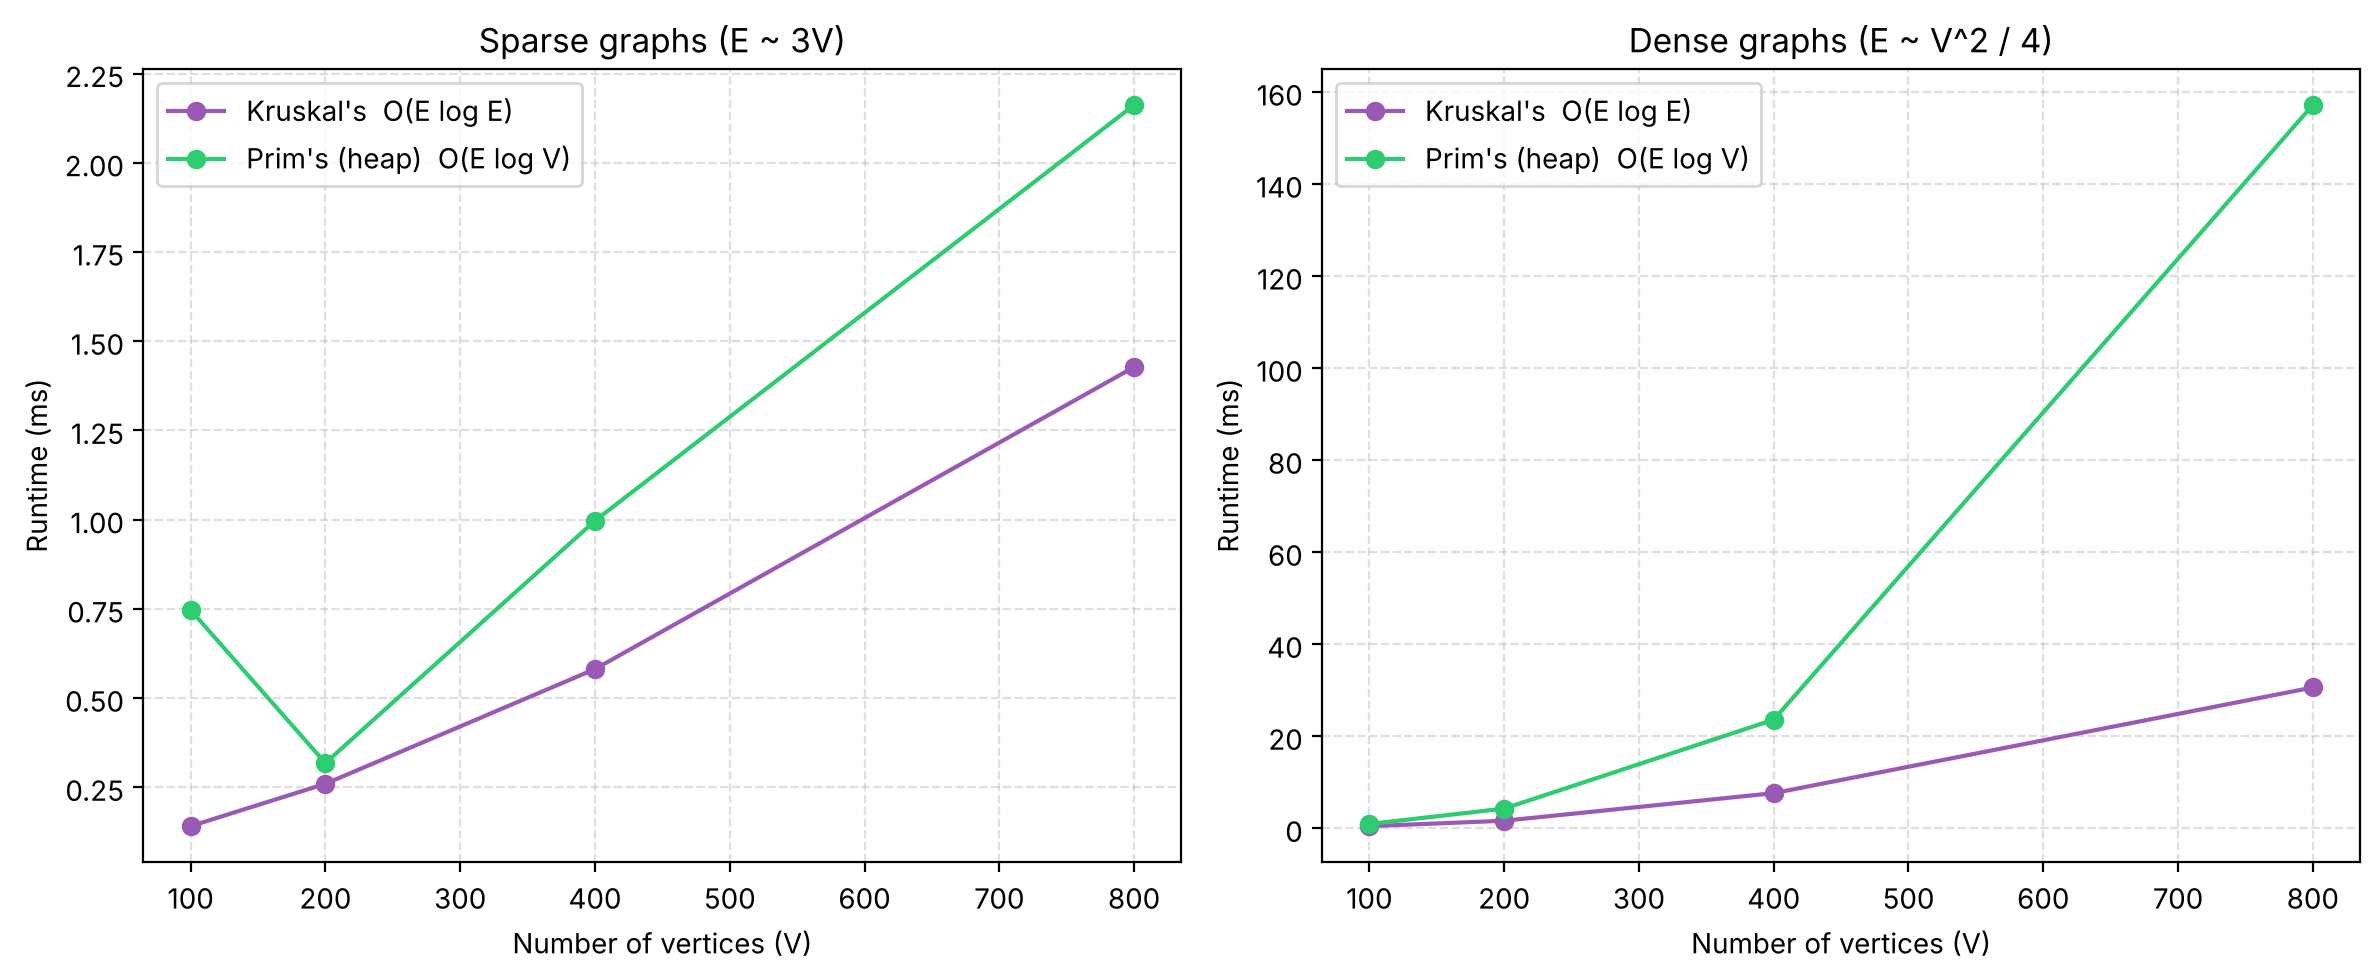

In [11]:
# --- Side-by-side charts: sparse vs dense ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(sizes, sparse_k, marker='o', label="Kruskal's  O(E log E)", color='#9b59b6')
axes[0].plot(sizes, sparse_p, marker='o', label="Prim's (heap)  O(E log V)", color='#2ecc71')
axes[0].set_title("Sparse graphs (E ~ 3V)")

axes[1].plot(sizes, dense_k, marker='o', label="Kruskal's  O(E log E)", color='#9b59b6')
axes[1].plot(sizes, dense_p, marker='o', label="Prim's (heap)  O(E log V)", color='#2ecc71')
axes[1].set_title("Dense graphs (E ~ V^2 / 4)")

for ax in axes:
    ax.set_xlabel("Number of vertices (V)")
    ax.set_ylabel("Runtime (ms)")
    ax.legend()
    ax.grid(True, ls="--", alpha=0.4)

plt.tight_layout()
plt.show()


## Summary Table

| Algorithm              | Time Complexity | Space Complexity | Key Data Structure        | Handles Disconnected Graphs?          |
|--------------------------|-------------------|---------------------|-----------------------------|-------------------------------------------|
| Kruskal's                | O(E log E) = O(E log V) | O(V + E)       | Sorted edge list + Union-Find | Yes (gives a minimum spanning forest)     |
| Prim's (min-heap)        | O(E log V)         | O(V + E)             | Min-heap                    | Only the start vertex's component         |

Where `V` = number of vertices, `E` = number of edges.

**Notes:**
- Kruskal's is a **greedy** algorithm that builds the MST by **merging components**: it always adds the globally cheapest edge that connects two different components. This is correct thanks to the **cut property** — the lightest edge crossing any cut belongs to some MST.
- Cycle detection with **Union-Find** (path compression + union by rank) is what keeps the main loop nearly `O(1)` per edge; without those optimizations, `find` can degrade to `O(V)`.
- The **sorting step dominates** the running time. If the edges are already sorted (or weights are small integers, allowing counting sort), Kruskal's becomes close to linear.
- Kruskal's works directly on an **edge list**, so it's convenient when the graph is given as edges, and it is a natural fit for **sparse graphs**.
- In the experiment above, Kruskal's was faster than **heap-based** Prim's on both sparse and dense random graphs. Part of the reason is implementation: Python's built-in sort runs in C, while heap-based Prim's does many individual heap pushes in pure Python. The classic textbook advice that Prim's suits dense graphs really applies to the **array-based `O(V^2)` version** (see the Prim's notebook), not the heap version. Real timings depend on the language, the implementation, and the graph.
- If several edges share the same weight, the MST may not be unique, but its **total weight** always is.
